# Electricity Consumption Intelligence System ⚡
### Energy Analytics Dashboard — minute-level household power + weather

**Dataset:** `energy_weather_raw_data.csv` (one reading per minute: active/reactive/apparent power, voltage, current, power factor, plus matched weather).

**Dashboard sections:** ⚡ energy consumption · 📈 hourly/daily trends · 📅 monthly patterns · 🌡️ weather/temperature relationships · 📊 peak consumption periods · 🤖 ML-based energy estimation · 💡 energy-saving insights.

**Honesty notes (read before reporting any score)**
- `active_power` = voltage × current × power factor almost exactly (correlation 0.99999999). Using current/voltage/power factor to "predict" power would be a physics identity, not machine learning, so those same-minute values are **never** used to estimate the same minute's power.
- Two ML tasks are reported side by side: **(A)** a real *next-hour forecast* and **(B)** a *live end-of-hour estimate* made part-way through the hour. They are different problems with very different scores, and the notebook shows both plus a weather ablation.
- Chronological 70/15/15 split; the test set is evaluated once, after model selection on validation.
- Costs use an **assumed** tariff you can edit (`TARIFF_PER_KWH`); the dataset has no prices.

In [1]:
from pathlib import Path
import json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor, ExtraTreesRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
import joblib

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 170)

PROJECT_DIR = Path.cwd()
SEARCH_DIRS = [PROJECT_DIR, PROJECT_DIR / "dataset", PROJECT_DIR.parent, PROJECT_DIR.parent / "dataset"]
DATA_FILE = next((p / "energy_weather_raw_data.csv" for p in SEARCH_DIRS if (p / "energy_weather_raw_data.csv").exists()), None)
if DATA_FILE is None:
    raise FileNotFoundError("Place energy_weather_raw_data.csv beside this notebook or inside a dataset/ folder.")

OUT, MODELS = PROJECT_DIR / "outputs", PROJECT_DIR / "models"
FIG_DIR, DASH_DIR = OUT / "figures", OUT / "dashboard_data"
for p in (OUT, MODELS, FIG_DIR, DASH_DIR): p.mkdir(exist_ok=True)

TARIFF_PER_KWH = 0.12     # ASSUMPTION for illustrative cost figures; edit to your local tariff
MIN_READINGS = 40         # an hour needs >= 40 of 60 minute readings to count as a valid hour
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
SEASON = {12:"Winter",1:"Winter",2:"Winter",3:"Spring",4:"Spring",5:"Spring",6:"Summer",7:"Summer",8:"Summer",9:"Autumn",10:"Autumn",11:"Autumn"}

C = dict(indigo="#4F46E5", teal="#0D9488", amber="#F59E0B", rose="#E11D48", sky="#0EA5E9", slate="#334155", mist="#E2E8F0")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 10.5, "font.size": 10,
    "axes.prop_cycle": plt.cycler(color=[C["indigo"], C["teal"], C["amber"], C["rose"], C["sky"], C["slate"]]),
})
def save_fig(fig, name): fig.savefig(FIG_DIR / f"{name}.png")
print("Dataset:", DATA_FILE.resolve())

Dataset: C:\Users\Satya Sagar Nayak\OneDrive\Desktop\mlpa-45\mlpa-45\energy_weather_raw_data.csv


## 1. Load and audit the raw minute data

In [2]:
raw = pd.read_csv(DATA_FILE, parse_dates=["date"])
n_dup = int(raw["date"].duplicated().sum())
raw = raw.drop_duplicates("date").sort_values("date").reset_index(drop=True)
step = raw["date"].diff().dt.total_seconds().div(60)

print("Rows:", f"{len(raw):,}", "| columns:", raw.shape[1])
print("Period:", raw["date"].min(), "->", raw["date"].max())
print("Duplicate timestamps removed:", n_dup, "| missing cells:", int(raw.isna().sum().sum()))
print(f"Minute spacing: {(step == 1).mean()*100:.2f}% of readings are exactly 1 minute apart; gaps > 60 min: {int((step > 60).sum())}")
gaps = raw.loc[step > 60, ["date"]].assign(gap_minutes=step[step > 60]).reset_index(drop=True)
display(gaps)
phys = np.corrcoef(raw["active_power"], raw["voltage"] * raw["current"] * raw["power_factor"])[0, 1]
print(f"corr(active_power, V x I x power_factor) = {phys:.8f}  -> same-minute V/I/PF would leak the target, so they are not used as inputs")
print(f"Weather values change in {(raw['temp'].diff() != 0).mean()*100:.0f}% of minutes (feed updates every few minutes, repeated in between)")
display(raw.describe().T[["mean", "std", "min", "50%", "max"]].round(3))

Rows: 605,257 | columns: 19
Period: 2022-11-05 14:05:00 -> 2024-01-05 23:59:00
Duplicate timestamps removed: 3 | missing cells: 0
Minute spacing: 99.80% of readings are exactly 1 minute apart; gaps > 60 min: 6


,date,gap_minutes
0,2022-11-11 19:16:00,280.0
1,2022-11-12 19:16:00,280.0
2,2023-02-09 18:40:00,128.0
3,2023-07-07 10:44:00,956.0
4,2023-08-22 11:55:00,99.0
5,2023-09-11 18:00:00,1573.0


corr(active_power, V x I x power_factor) = 1.00000000  -> same-minute V/I/PF would leak the target, so they are not used as inputs
Weather values change in 21% of minutes (feed updates every few minutes, repeated in between)


,mean,std,min,50%,max
date,2023-06-06 14:27:06.055840768,NaN,2022-11-05 14:05:00,2023-06-05 12:06:00,2024-01-05 23:59:00
active_power,286.019681,189.546087,24.4,250.3,2900.0
current,2.587306,1.591398,0.3,2.29,24.41
voltage,125.417317,4.390611,107.6,124.4,135.5
reactive_power,132.538097,71.030393,4.73,128.5,1293.58
apparent_power,321.839616,191.744352,37.14,286.44,2931.64
power_factor,0.854202,0.114629,0.2018,0.8917,1.0
temp,19.525239,6.607348,-5.56,19.49,39.37
feels_like,18.712608,6.722513,-6.13,18.9,36.7
temp_min,18.086947,6.51921,-5.56,18.06,37.59


## 2. Build the hourly and daily analytics tables

In [3]:
raw["hour_ts"] = raw["date"].dt.floor("h")
hourly = raw.groupby("hour_ts").agg(
    readings=("active_power", "size"), avg_w=("active_power", "mean"), peak_w=("active_power", "max"),
    min_w=("active_power", "min"), std_w=("active_power", "std"), reactive_var=("reactive_power", "mean"),
    voltage=("voltage", "mean"), power_factor=("power_factor", "mean"),
    temp=("temp", "mean"), feels_like=("feels_like", "mean"), humidity=("humidity", "mean"),
    pressure=("pressure", "mean"), wind=("speed", "mean"), temp_next_hour=("temp_t+1", "last"),
    condition=("main", lambda s: s.mode().iat[0]),
)
hourly = hourly.reindex(pd.date_range(hourly.index.min(), hourly.index.max(), freq="h"))
hourly["kwh"] = np.where(hourly["readings"] >= MIN_READINGS, hourly["avg_w"] / 1000.0, np.nan)   # average kW over 1 h = kWh
hourly["hour"], hourly["dow"], hourly["month"] = hourly.index.hour, hourly.index.dayofweek, hourly.index.month
hourly["is_weekend"] = (hourly["dow"] >= 5).astype(int)
hourly["season"] = hourly["month"].map(SEASON)
hourly["hsin"], hourly["hcos"] = np.sin(2*np.pi*hourly["hour"]/24), np.cos(2*np.pi*hourly["hour"]/24)
print("Hourly grid:", len(hourly), "hours | valid hours:", int(hourly["kwh"].notna().sum()),
      "| missing/low-coverage hours:", int(hourly["kwh"].isna().sum()))

d = hourly.assign(date=hourly.index.floor("D"))
daily = d.groupby("date").agg(kwh=("kwh", "sum"), valid_hours=("kwh", "count"), temp=("temp", "mean"),
                              temp_max=("temp", "max"), temp_min=("temp", "min"), humidity=("humidity", "mean"),
                              wind=("wind", "mean"), peak_w=("peak_w", "max"))
daily = daily[daily["valid_hours"] == 24].drop(columns="valid_hours")      # complete days only
daily["dow"], daily["month"] = daily.index.dayofweek, daily.index.month
print("Complete days:", len(daily))

# Cooling sensitivity: daily kWh = a + b * max(temp - T0, 0), T0 chosen by least squares
best = None
y_d, sst = daily["kwh"].to_numpy(), ((daily["kwh"] - daily["kwh"].mean())**2).sum()
for t0 in np.arange(10, 27.01, 0.5):
    A = np.column_stack([np.ones(len(daily)), np.maximum(daily["temp"].to_numpy() - t0, 0)])
    coef = np.linalg.lstsq(A, y_d, rcond=None)[0]; sse = ((A @ coef - y_d)**2).sum()
    if best is None or sse < best["sse"]: best = dict(sse=sse, t0=float(t0), base=float(coef[0]), slope=float(coef[1]), r2=float(1 - sse/sst))
cool = best
print(f"Cooling model: base {cool['base']:.1f} kWh/day, +{cool['slope']:.2f} kWh/day per °C above {cool['t0']:.1f} °C (daily R² {cool['r2']:.2f})")

hourly.drop(columns=["condition"]).assign(condition=hourly["condition"]).to_csv(OUT / "hourly_dataset.csv")
daily.to_csv(OUT / "daily_dataset.csv")

Hourly grid: 10234 hours | valid hours: 10106 | missing/low-coverage hours: 128
Complete days: 393
Cooling model: base 5.4 kWh/day, +0.62 kWh/day per °C above 19.5 °C (daily R² 0.52)


## 3. ⚡ Energy consumption overview

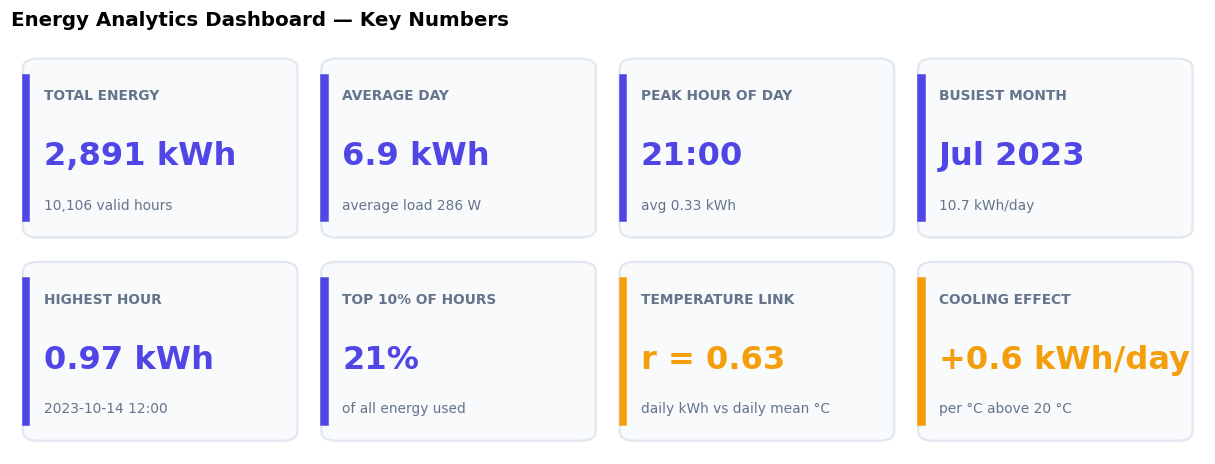

In [4]:
ok = hourly["kwh"].dropna()
hour_avg = hourly.groupby("hour")["kwh"].mean()
month_daily = daily.groupby(daily.index.to_period("M")).agg(kwh=("kwh", "mean"), temp=("temp", "mean"), days=("kwh", "size"))
month_daily = month_daily[month_daily["days"] >= 15]
sorted_kwh = np.sort(ok.to_numpy())[::-1]
top10_share = sorted_kwh[: int(len(sorted_kwh) * 0.10)].sum() / sorted_kwh.sum()
peak_ts = ok.idxmax()
r_temp = daily[["kwh", "temp"]].corr().iloc[0, 1]

kpis = {
    "period_start": str(raw["date"].min()), "period_end": str(raw["date"].max()),
    "valid_hours": int(len(ok)), "total_energy_kwh": float(ok.sum()),
    "avg_daily_kwh": float(daily["kwh"].mean()), "avg_load_w": float(ok.mean() * 1000),
    "peak_hour_of_day": int(hour_avg.idxmax()), "peak_hour_avg_kwh": float(hour_avg.max()),
    "quietest_hour_of_day": int(hour_avg.idxmin()),
    "busiest_month": str(month_daily["kwh"].idxmax()), "busiest_month_avg_daily_kwh": float(month_daily["kwh"].max()),
    "highest_hour_kwh": float(ok.max()), "highest_hour_timestamp": str(peak_ts),
    "top10pct_hours_energy_share": float(top10_share),
    "daily_temp_correlation": float(r_temp),
    "cooling_slope_kwh_per_day_per_c": cool["slope"], "cooling_threshold_c": cool["t0"],
}
json.dump(kpis, open(DASH_DIR / "kpis.json", "w"), indent=2)

cards = [
    ("TOTAL ENERGY", f"{kpis['total_energy_kwh']:,.0f} kWh", f"{kpis['valid_hours']:,} valid hours"),
    ("AVERAGE DAY", f"{kpis['avg_daily_kwh']:.1f} kWh", f"average load {kpis['avg_load_w']:.0f} W"),
    ("PEAK HOUR OF DAY", f"{kpis['peak_hour_of_day']:02d}:00", f"avg {kpis['peak_hour_avg_kwh']:.2f} kWh"),
    ("BUSIEST MONTH", pd.Period(kpis["busiest_month"]).strftime("%b %Y"), f"{kpis['busiest_month_avg_daily_kwh']:.1f} kWh/day"),
    ("HIGHEST HOUR", f"{kpis['highest_hour_kwh']:.2f} kWh", kpis["highest_hour_timestamp"][:16]),
    ("TOP 10% OF HOURS", f"{top10_share*100:.0f}%", "of all energy used"),
    ("TEMPERATURE LINK", f"r = {r_temp:.2f}", "daily kWh vs daily mean °C"),
    ("COOLING EFFECT", f"+{cool['slope']:.1f} kWh/day", f"per °C above {cool['t0']:.0f} °C"),
]
accent = [C["indigo"]]*6 + [C["amber"]]*2
fig, ax = plt.subplots(figsize=(14, 4.8)); ax.axis("off"); ax.set_xlim(0, 4); ax.set_ylim(0, 2); ax.grid(False)
for i, (label, value, sub) in enumerate(cards):
    r, col = divmod(i, 4); x, y = col + 0.04, (1 - r) + 0.06
    ax.add_patch(FancyBboxPatch((x, y), 0.92, 0.88, boxstyle="round,pad=0,rounding_size=0.05", fc="#F8FAFC", ec=C["mist"], lw=1.5))
    ax.add_patch(Rectangle((x, y + 0.08), 0.022, 0.72, color=accent[i]))
    ax.text(x + 0.07, y + 0.68, label, fontsize=9, color="#64748B", fontweight="bold")
    ax.text(x + 0.07, y + 0.36, value, fontsize=21, color=accent[i], fontweight="bold")
    ax.text(x + 0.07, y + 0.14, sub, fontsize=9, color="#64748B")
ax.set_title("Energy Analytics Dashboard — Key Numbers", loc="left", pad=14)
save_fig(fig, "00_kpi_cards"); plt.show()

## 4. 📈 Hourly and daily trends

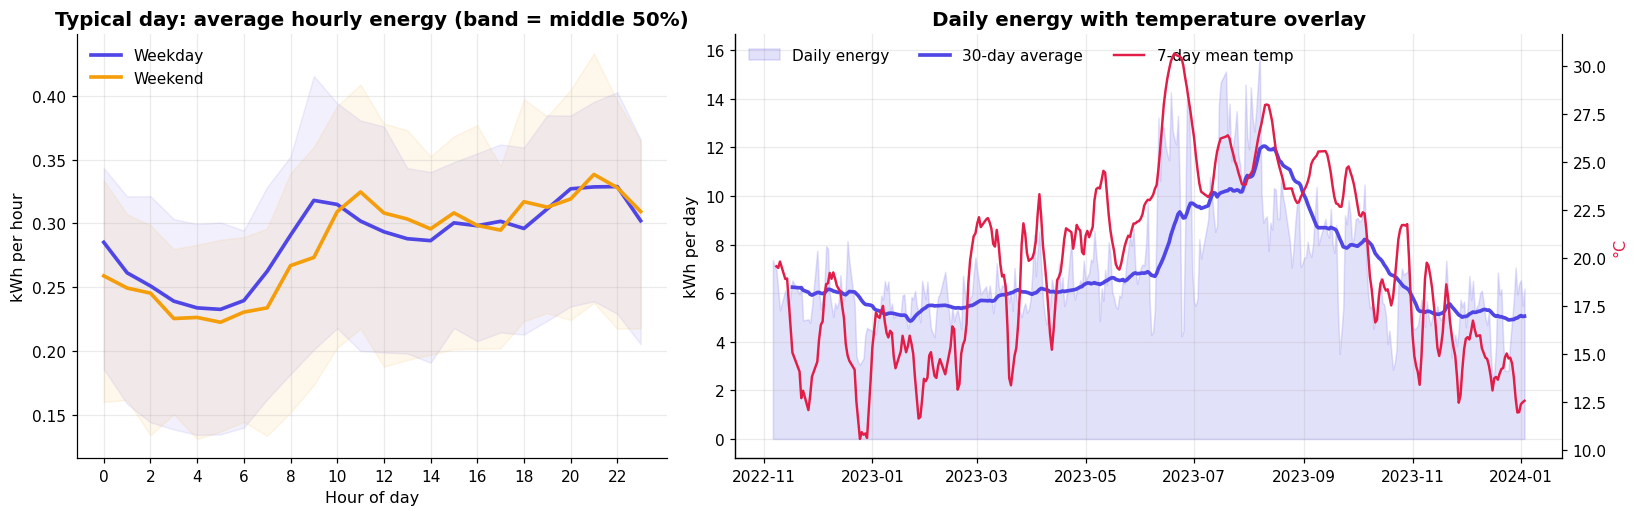

Weekday average day: 6.88 kWh | weekend: 6.82 kWh


In [5]:
prof = hourly.groupby(["is_weekend", "hour"])["kwh"].agg(["mean", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
prof.columns = ["mean", "q25", "q75"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.4]})
for flag, name, colr in [(0, "Weekday", C["indigo"]), (1, "Weekend", C["amber"])]:
    g = prof.loc[flag]
    axes[0].plot(g.index, g["mean"], lw=2.4, color=colr, label=name)
    axes[0].fill_between(g.index, g["q25"], g["q75"], color=colr, alpha=0.08)
axes[0].set(title="Typical day: average hourly energy (band = middle 50%)", xlabel="Hour of day", ylabel="kWh per hour", xticks=range(0, 24, 2))
axes[0].legend(frameon=False)

daily["rolling_30d"] = daily["kwh"].rolling(30, min_periods=10).mean()
axes[1].fill_between(daily.index, daily["kwh"], color=C["indigo"], alpha=0.16, label="Daily energy")
axes[1].plot(daily.index, daily["rolling_30d"], color=C["indigo"], lw=2.4, label="30-day average")
axes[1].set(title="Daily energy with temperature overlay", ylabel="kWh per day")
ax2 = axes[1].twinx(); ax2.grid(False); ax2.spines["right"].set_visible(True)
ax2.plot(daily.index, daily["temp"].rolling(7, min_periods=3).mean(), color=C["rose"], lw=1.6, label="7-day mean temp")
ax2.set_ylabel("°C", color=C["rose"])
h1, l1 = axes[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
axes[1].legend(h1 + h2, l1 + l2, frameon=False, loc="upper left", ncol=3)
plt.tight_layout(); save_fig(fig, "01_hourly_daily_trends"); plt.show()
prof.reset_index().to_csv(DASH_DIR / "hourly_profile_weekday_weekend.csv", index=False)
daily.reset_index().to_csv(DASH_DIR / "daily_with_rolling.csv", index=False)
print(f"Weekday average day: {daily[daily.dow<5]['kwh'].mean():.2f} kWh | weekend: {daily[daily.dow>=5]['kwh'].mean():.2f} kWh")

## 5. 📅 Monthly patterns

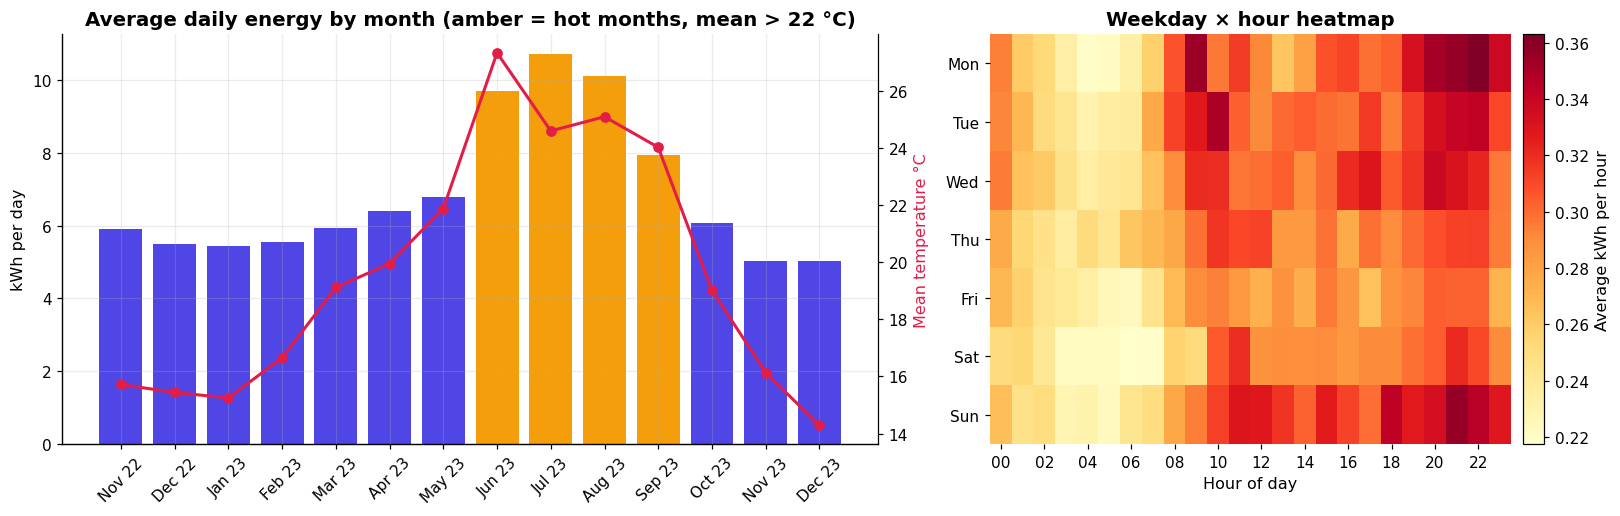

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
labels = [p.strftime("%b %y") for p in month_daily.index]
bars = axes[0].bar(labels, month_daily["kwh"], color=[C["amber"] if t > 22 else C["indigo"] for t in month_daily["temp"]])
axes[0].set(title="Average daily energy by month (amber = hot months, mean > 22 °C)", ylabel="kWh per day")
axes[0].tick_params(axis="x", rotation=45)
axb = axes[0].twinx(); axb.grid(False); axb.spines["right"].set_visible(True)
axb.plot(labels, month_daily["temp"], color=C["rose"], marker="o", lw=2); axb.set_ylabel("Mean temperature °C", color=C["rose"])

heat = hourly.pivot_table(index="dow", columns="hour", values="kwh", aggfunc="mean"); heat.index = DOW
im = axes[1].imshow(heat.values, aspect="auto", cmap="YlOrRd"); axes[1].grid(False)
axes[1].set_xticks(range(0, 24, 2)); axes[1].set_xticklabels([f"{h:02d}" for h in range(0, 24, 2)])
axes[1].set_yticks(range(7)); axes[1].set_yticklabels(DOW)
for sp in axes[1].spines.values(): sp.set_visible(False)
fig.colorbar(im, ax=axes[1], pad=0.02).set_label("Average kWh per hour")
axes[1].set(title="Weekday × hour heatmap", xlabel="Hour of day")
plt.tight_layout(); save_fig(fig, "02_monthly_patterns"); plt.show()
month_daily.reset_index().astype({"index": str} if "index" in month_daily.reset_index().columns else {}).to_csv(DASH_DIR / "monthly_summary.csv", index=False)
heat.to_csv(DASH_DIR / "heatmap_weekday_hour.csv")

## 6. 🌡️ Weather and temperature relationships

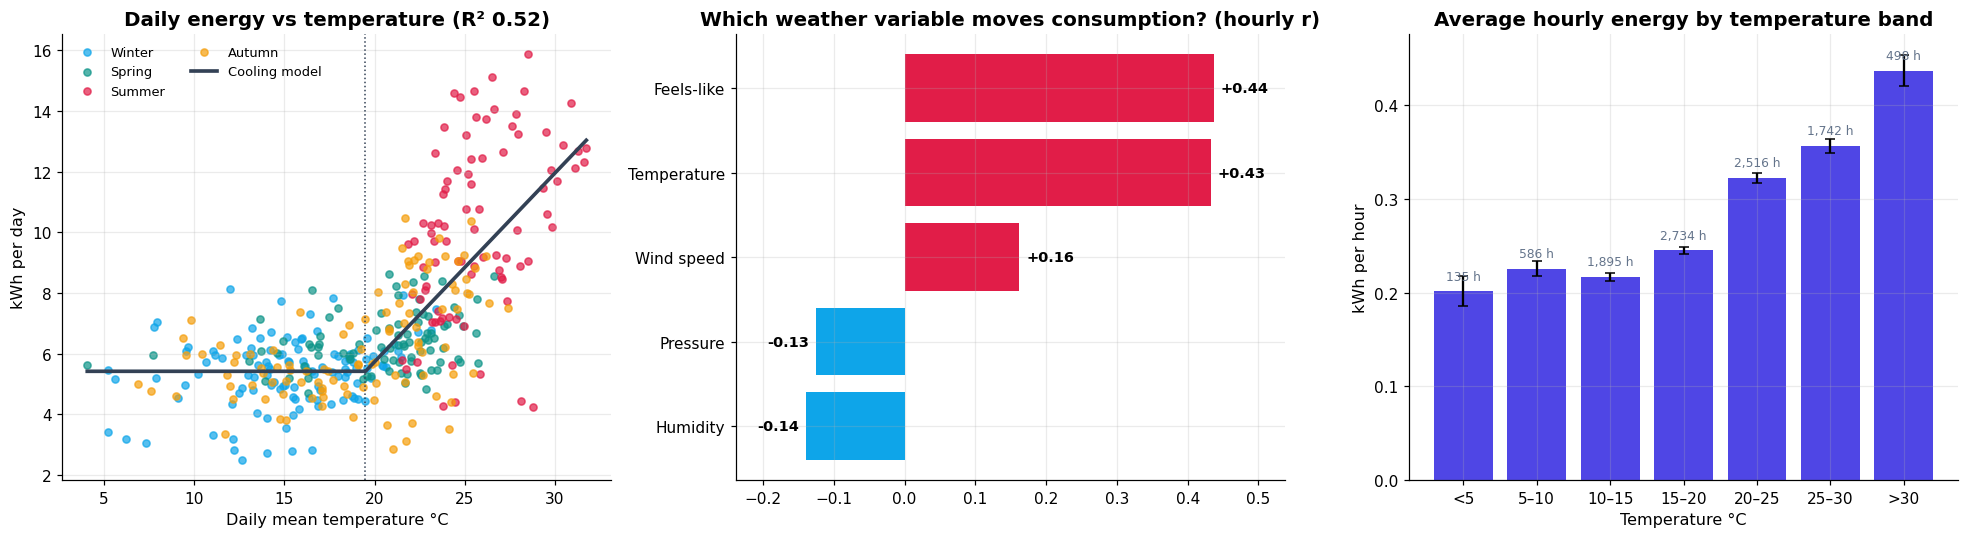

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
season_col = {"Winter": C["sky"], "Spring": C["teal"], "Summer": C["rose"], "Autumn": C["amber"]}
for s, colr in season_col.items():
    m = daily["month"].map(SEASON) == s
    axes[0].scatter(daily.loc[m, "temp"], daily.loc[m, "kwh"], s=22, alpha=0.7, color=colr, label=s)
xs = np.linspace(daily["temp"].min(), daily["temp"].max(), 200)
axes[0].plot(xs, cool["base"] + cool["slope"] * np.maximum(xs - cool["t0"], 0), color=C["slate"], lw=2.4, label="Cooling model")
axes[0].axvline(cool["t0"], color=C["slate"], ls=":", lw=1)
axes[0].set(title=f"Daily energy vs temperature (R² {cool['r2']:.2f})", xlabel="Daily mean temperature °C", ylabel="kWh per day")
axes[0].legend(frameon=False, ncol=2, fontsize=8.5)

wcols = {"temp": "Temperature", "feels_like": "Feels-like", "humidity": "Humidity", "pressure": "Pressure", "wind": "Wind speed"}
corr = pd.Series({lab: hourly["kwh"].corr(hourly[c]) for c, lab in wcols.items()}).sort_values()
axes[1].barh(corr.index, corr.values, color=[C["rose"] if v > 0 else C["sky"] for v in corr.values])
for i, v in enumerate(corr.values): axes[1].text(v + (0.01 if v > 0 else -0.01), i, f"{v:+.2f}", va="center", ha="left" if v > 0 else "right", fontsize=9.5, fontweight="bold")
axes[1].set(title="Which weather variable moves consumption? (hourly r)", xlim=(min(corr.min() - 0.1, -0.1), max(corr.max() + 0.1, 0.1)))

bins = [-10, 5, 10, 15, 20, 25, 30, 45]; names = ["<5", "5–10", "10–15", "15–20", "20–25", "25–30", ">30"]
hourly["temp_band"] = pd.cut(hourly["temp"], bins=bins, labels=names)
tb = hourly.groupby("temp_band", observed=True)["kwh"].agg(["mean", "count", "sem"])
axes[2].bar(tb.index.astype(str), tb["mean"], yerr=1.96 * tb["sem"], color=C["indigo"], capsize=3)
for i, (m_, n_) in enumerate(zip(tb["mean"], tb["count"])): axes[2].text(i, m_ + 0.012, f"{n_:,} h", ha="center", fontsize=8, color="#64748B")
axes[2].set(title="Average hourly energy by temperature band", xlabel="Temperature °C", ylabel="kWh per hour")
plt.tight_layout(); save_fig(fig, "03_weather_relationships"); plt.show()
corr.rename("correlation").to_csv(DASH_DIR / "weather_correlations.csv")
tb.reset_index().to_csv(DASH_DIR / "temperature_bands.csv", index=False)

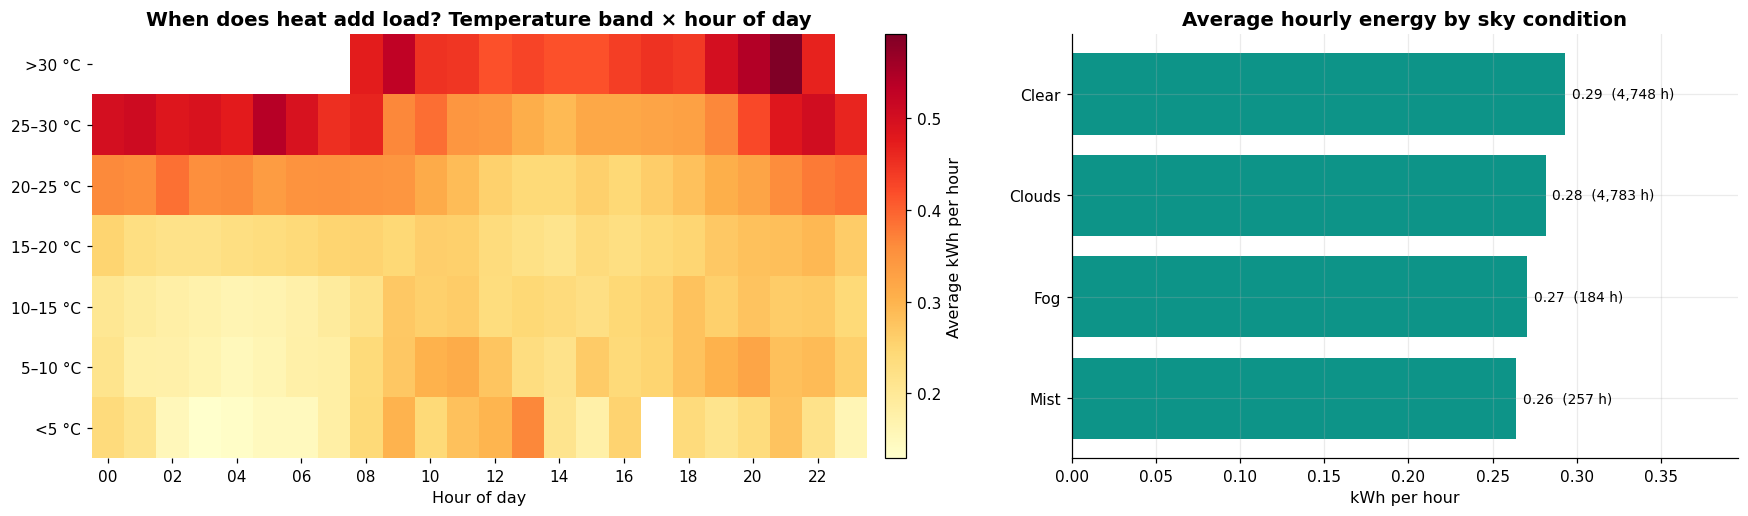

Note: sky-condition differences are partly seasonal (clear skies are more common in hot months), so use the temperature charts for causal-style reading.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
th = hourly.pivot_table(index="temp_band", columns="hour", values="kwh", aggfunc="mean", observed=True)
im = axes[0].imshow(th.values, aspect="auto", cmap="YlOrRd", origin="lower"); axes[0].grid(False)
axes[0].set_xticks(range(0, 24, 2)); axes[0].set_xticklabels([f"{h:02d}" for h in range(0, 24, 2)])
axes[0].set_yticks(range(len(th.index))); axes[0].set_yticklabels([f"{t} °C" for t in th.index])
for sp in axes[0].spines.values(): sp.set_visible(False)
fig.colorbar(im, ax=axes[0], pad=0.02).set_label("Average kWh per hour")
axes[0].set(title="When does heat add load? Temperature band × hour of day", xlabel="Hour of day")

cond = hourly.groupby("condition")["kwh"].agg(["mean", "count"]); cond = cond[cond["count"] >= 100].sort_values("mean")
axes[1].barh(cond.index, cond["mean"], color=C["teal"])
for i, (m_, n_) in enumerate(zip(cond["mean"], cond["count"])): axes[1].text(m_ + 0.004, i, f"{m_:.2f}  ({n_:,} h)", va="center", fontsize=9)
axes[1].set(title="Average hourly energy by sky condition", xlabel="kWh per hour", xlim=(0, cond["mean"].max() * 1.35))
plt.tight_layout(); save_fig(fig, "04_temperature_hour_and_conditions"); plt.show()
th.to_csv(DASH_DIR / "temperature_band_by_hour.csv"); cond.to_csv(DASH_DIR / "sky_condition_summary.csv")
print("Note: sky-condition differences are partly seasonal (clear skies are more common in hot months), so use the temperature charts for causal-style reading.")

## 7. 📊 Peak consumption periods

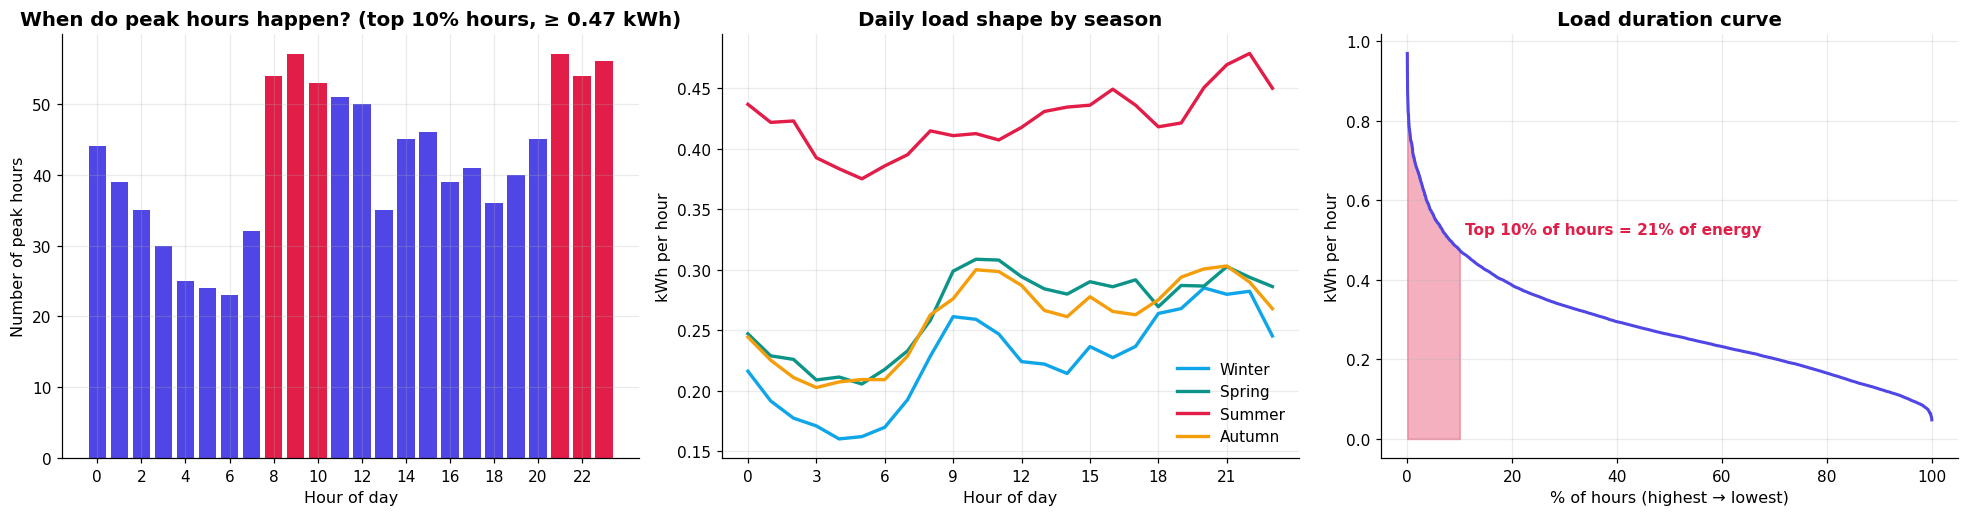

Top 10 peak hours


,hour_start,kwh,peak_w,temp,humidity
0,2023-10-14 12:00:00,0.97,2900.0,20.40,75.28
1,2023-07-17 16:00:00,0.95,976.8,31.50,28.72
2,2023-06-28 00:00:00,0.91,920.5,23.07,39.90
3,2023-07-17 17:00:00,0.90,962.9,31.42,28.90
4,2023-07-15 14:00:00,0.89,955.1,31.56,32.00
5,2023-08-07 22:00:00,0.89,922.0,27.46,42.63
6,2023-06-18 17:00:00,0.87,896.1,35.99,18.20
7,2023-08-07 09:00:00,0.87,2210.4,27.08,39.84
8,2023-08-07 21:00:00,0.86,922.0,28.45,37.57
9,2023-08-05 13:00:00,0.86,908.8,33.03,20.61


Top 10 peak days


,day,kwh,temp,temp_max
0,2023-08-07,15.87,28.51,33.76
1,2023-07-19,15.12,26.50,32.31
2,2023-07-16,14.67,25.51,31.83
3,2023-08-06,14.64,28.26,33.91
4,2023-07-30,14.58,24.42,29.59
5,2023-08-02,14.47,24.73,29.53
6,2023-06-18,14.26,30.91,38.06
7,2023-06-28,14.07,26.62,31.92
8,2023-06-27,13.92,27.86,33.88
9,2023-07-21,13.80,25.61,31.53


Evening window 18:00–22:59 holds 23% of all energy.


In [9]:
p90 = ok.quantile(0.90)
peaks = hourly[hourly["kwh"] >= p90]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
cnt = peaks.groupby("hour").size().reindex(range(24), fill_value=0)
axes[0].bar(cnt.index, cnt.values, color=[C["rose"] if v >= cnt.quantile(.75) else C["indigo"] for v in cnt.values])
axes[0].set(title=f"When do peak hours happen? (top 10% hours, ≥ {p90:.2f} kWh)", xlabel="Hour of day", ylabel="Number of peak hours", xticks=range(0, 24, 2))

for s, colr in season_col.items():
    g = hourly[hourly["season"] == s].groupby("hour")["kwh"].mean()
    axes[1].plot(g.index, g.values, lw=2.2, color=colr, label=s)
axes[1].set(title="Daily load shape by season", xlabel="Hour of day", ylabel="kWh per hour", xticks=range(0, 24, 3)); axes[1].legend(frameon=False)

pct = np.linspace(0, 100, len(sorted_kwh)); m10 = pct <= 10
axes[2].plot(pct, sorted_kwh, color=C["indigo"], lw=2); axes[2].fill_between(pct[m10], sorted_kwh[m10], color=C["rose"], alpha=0.35)
axes[2].text(11, p90 + 0.04, f"Top 10% of hours = {top10_share*100:.0f}% of energy", color=C["rose"], fontweight="bold")
axes[2].set(title="Load duration curve", xlabel="% of hours (highest → lowest)", ylabel="kWh per hour")
plt.tight_layout(); save_fig(fig, "05_peak_periods"); plt.show()

top_hours = hourly.nlargest(10, "kwh")[["kwh", "peak_w", "temp", "humidity"]].round(2).reset_index(names="hour_start")
top_days = daily.nlargest(10, "kwh")[["kwh", "temp", "temp_max"]].round(2).reset_index(names="day")
print("Top 10 peak hours"); display(top_hours)
print("Top 10 peak days"); display(top_days)
evening = hourly[hourly["hour"].between(18, 22)]["kwh"].sum() / ok.sum()
print(f"Evening window 18:00–22:59 holds {evening*100:.0f}% of all energy.")
top_hours.to_csv(DASH_DIR / "top_peak_hours.csv", index=False); top_days.to_csv(DASH_DIR / "top_peak_days.csv", index=False)
cnt.rename("peak_hours").to_csv(DASH_DIR / "peak_hours_by_hour.csv")

## 8. 💡 Energy-saving insights

,action,kwh_year,kind,cost_year
0,Cut cooling energy by 10%,53.0,saved,6.4
1,Trim always-on base load by 20%,101.6,saved,12.2
2,Shift 15% of peak-hour energy off-peak,77.2,shifted,9.3


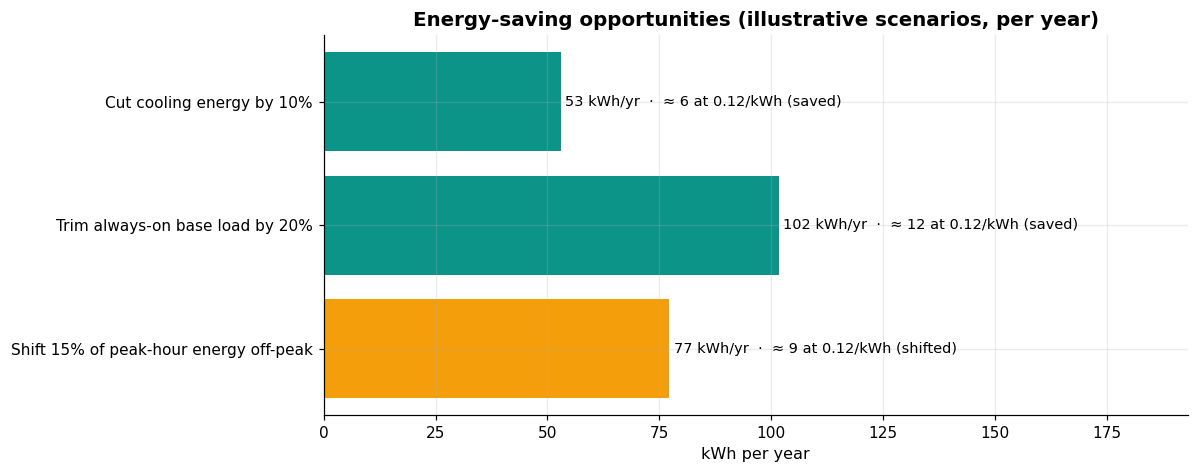

💡 Cooling drives the summer bill: 21% of energy — Above 19.5 °C each extra degree adds about 0.6 kWh/day. A 10% cut in cooling energy saves about 53 kWh/year.
💡 Evening peak: 23% in 18:00–23:00 — The top 10% of hours use 21% of energy; moving 15% of that load off-peak shifts about 77 kWh/year (a saving only under time-of-use pricing).
💡 Always-on base load: 58 W — The 5th-percentile power is 58 W, about 508 kWh/year (20% of use). Trimming 20% of it saves about 102 kWh/year.
💡 Weekend effect: -1% vs weekdays — Average weekend day 6.8 kWh vs weekday 6.9 kWh.

Scenarios use the percentages shown above as assumptions, not measured results. Tariff is an assumed value.


In [10]:
annual_kwh = daily["kwh"].mean() * 365
# 1) Always-on base load (5th percentile of minute power)
base_w = float(raw["active_power"].quantile(0.05)); base_annual = base_w * 8760 / 1000
# 2) Cooling-related energy from the temperature model
cool_kwh_total = float((cool["slope"] * np.maximum(daily["temp"] - cool["t0"], 0)).sum())
cool_share = cool_kwh_total / daily["kwh"].sum(); cool_annual = cool_share * annual_kwh
# 3) Peak window energy (top 10% hours) that could be shifted
peak_share = top10_share; peak_annual = peak_share * annual_kwh
# 4) Weekday vs weekend
wk, we = daily[daily.dow < 5]["kwh"].mean(), daily[daily.dow >= 5]["kwh"].mean()

scenarios = pd.DataFrame([
    {"action": "Cut cooling energy by 10%",          "kwh_year": 0.10 * cool_annual, "kind": "saved"},
    {"action": "Trim always-on base load by 20%",    "kwh_year": 0.20 * base_annual, "kind": "saved"},
    {"action": "Shift 15% of peak-hour energy off-peak", "kwh_year": 0.15 * peak_annual, "kind": "shifted"},
])
scenarios["cost_year"] = scenarios["kwh_year"] * TARIFF_PER_KWH
display(scenarios.round(1))

insights = [
    {"title": "Cooling drives the summer bill", "value": f"{cool_share*100:.0f}% of energy",
     "detail": f"Above {cool['t0']:.1f} °C each extra degree adds about {cool['slope']:.1f} kWh/day. A 10% cut in cooling energy saves about {0.10*cool_annual:,.0f} kWh/year."},
    {"title": "Evening peak", "value": f"{evening*100:.0f}% in 18:00–23:00",
     "detail": f"The top 10% of hours use {top10_share*100:.0f}% of energy; moving 15% of that load off-peak shifts about {0.15*peak_annual:,.0f} kWh/year (a saving only under time-of-use pricing)."},
    {"title": "Always-on base load", "value": f"{base_w:.0f} W",
     "detail": f"The 5th-percentile power is {base_w:.0f} W, about {base_annual:,.0f} kWh/year ({base_annual/annual_kwh*100:.0f}% of use). Trimming 20% of it saves about {0.20*base_annual:,.0f} kWh/year."},
    {"title": "Weekend effect", "value": f"{(we/wk-1)*100:+.0f}% vs weekdays",
     "detail": f"Average weekend day {we:.1f} kWh vs weekday {wk:.1f} kWh."},
]
json.dump({"tariff_per_kwh_assumed": TARIFF_PER_KWH, "insights": insights, "scenarios": scenarios.to_dict("records")},
          open(DASH_DIR / "insights.json", "w"), indent=2)

fig, ax = plt.subplots(figsize=(11, 4.4))
cols = [C["teal"] if k == "saved" else C["amber"] for k in scenarios["kind"]]
ax.barh(scenarios["action"], scenarios["kwh_year"], color=cols, hatch=None)
for i, (v, c_, k) in enumerate(zip(scenarios["kwh_year"], scenarios["cost_year"], scenarios["kind"])):
    ax.text(v + scenarios["kwh_year"].max()*0.01, i, f"{v:,.0f} kWh/yr  ·  ≈ {c_:,.0f} at {TARIFF_PER_KWH:.2f}/kWh ({k})", va="center", fontsize=9.5)
ax.set(title="Energy-saving opportunities (illustrative scenarios, per year)", xlabel="kWh per year", xlim=(0, scenarios["kwh_year"].max() * 1.9))
ax.invert_yaxis(); plt.tight_layout(); save_fig(fig, "06_saving_opportunities"); plt.show()
for it in insights: print(f"💡 {it['title']}: {it['value']} — {it['detail']}")
print("\nScenarios use the percentages shown above as assumptions, not measured results. Tariff is an assumed value.")

## 9. 🤖 ML-based energy estimation

Two tasks are evaluated, each on the same chronological split:

| Task | Question | Information used |
|---|---|---|
| **A. Next-hour forecast** | How much energy will the *next* hour use? | everything known up to the end of the current hour (+ weather, calendar) |
| **B. Live end-of-hour estimate** | How much energy will *this* hour use in total, given its first *m* minutes? | the first *m* minutes of the hour + history + weather |

Task B is a real use case (live projection / bill-to-date). Part of the target hour is already observed, so it is easier than a pure forecast. Never present it as a forecast.

In [11]:
f = hourly.copy()
f["condition_code"] = f["condition"].astype("category").cat.codes
for l in [1, 2, 3, 24, 48, 168]: f[f"lag{l}"] = f["kwh"].shift(l)
f["rm24"] = f["kwh"].rolling(24, min_periods=12).mean(); f["rm168"] = f["kwh"].rolling(168, min_periods=72).mean()

CAL = ["hour", "dow", "month", "hsin", "hcos"]
WX  = ["temp", "feels_like", "humidity", "pressure", "wind"]
WX_A = WX + ["temp_next_hour", "condition_code"]
CUR = ["kwh", "peak_w", "min_w", "std_w", "reactive_var", "voltage", "power_factor"]
LAGS = ["lag1", "lag2", "lag3", "lag24", "lag48", "lag168", "rm24", "rm168"]

def make_models():
    models = {
        "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=500, learning_rate=0.04, l2_regularization=1.0, random_state=42),
        "Extra Trees": ExtraTreesRegressor(n_estimators=250, min_samples_leaf=3, max_features=0.8, n_jobs=-1, random_state=42),
        "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=14, min_samples_leaf=3, max_features=0.8, n_jobs=-1, random_state=42),
    }
    try:
        from lightgbm import LGBMRegressor
        models["LightGBM"] = LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=30, subsample=0.85, subsample_freq=1, colsample_bytree=0.9, random_state=42, n_jobs=-1, verbosity=-1)
    except ImportError: pass
    try:
        from xgboost import XGBRegressor
        models["XGBoost"] = XGBRegressor(n_estimators=600, learning_rate=0.03, max_depth=6, subsample=0.85, colsample_bytree=0.9, random_state=42, n_jobs=-1, verbosity=0)
    except ImportError: pass
    try:
        from catboost import CatBoostRegressor
        models["CatBoost"] = CatBoostRegressor(iterations=600, learning_rate=0.04, depth=7, verbose=False, random_seed=42, allow_writing_files=False)
    except ImportError: pass
    return models

def metr(y_true, y_pred):
    return dict(R2=r2_score(y_true, y_pred), MAE=mean_absolute_error(y_true, y_pred), RMSE=float(np.sqrt(mean_squared_error(y_true, y_pred))))

def chrono_split(n): return int(n * 0.70), int(n * 0.85)
print("Available models:", list(make_models().keys()))

Available models: ['HistGradientBoosting', 'Extra Trees', 'Random Forest', 'LightGBM', 'XGBoost', 'CatBoost']


### 9A. Task A — next-hour forecast

In [12]:
featA = CUR + LAGS + CAL + WX_A
f["target_next_kwh"] = f["kwh"].shift(-1)
f["same_hour_last_week"] = f["kwh"].shift(167)      # baseline only (value of the target hour one week earlier)
dA = f.dropna(subset=featA + ["target_next_kwh"]).copy()
nA = len(dA); trA, vaA = chrono_split(nA)
XA, yA = dA[featA], dA["target_next_kwh"]
XA_tr, yA_tr, XA_va, yA_va, XA_te, yA_te = XA[:trA], yA[:trA], XA[trA:vaA], yA[trA:vaA], XA[vaA:], yA[vaA:]
print(f"Task A rows: train {trA:,} | val {vaA-trA:,} | test {nA-vaA:,}  ({dA.index[vaA].date()} → {dA.index[-1].date()} is the test period)")

# Baselines
hour_prof = dA.iloc[:trA].groupby((dA.iloc[:trA]["hour"] + 1) % 24)["target_next_kwh"].mean()
base_rows = []
for name, pred_fn in {
    "Persistence (next hour = this hour)": lambda d_: d_["kwh"],
    "Same hour last week":                 lambda d_: d_["same_hour_last_week"].fillna(d_["kwh"]),
    "Typical profile for that hour":       lambda d_: ((d_["hour"] + 1) % 24).map(hour_prof),
}.items():
    base_rows.append({"Model": name, "Validation R2": r2_score(yA_va, pred_fn(dA.iloc[trA:vaA])), "Test R2": r2_score(yA_te, pred_fn(dA.iloc[vaA:]))})

modelsA, valpredA, rowsA = make_models(), {}, []
for name, m in modelsA.items():
    m.fit(XA_tr, yA_tr); valpredA[name] = m.predict(XA_va)
    rowsA.append({"Model": name, **{f"Validation {k}": v for k, v in metr(yA_va, valpredA[name]).items()}})
VA = np.column_stack(list(valpredA.values()))
blenderA = Ridge(alpha=1.0, positive=True).fit(VA, yA_va)
rowsA.append({"Model": "Blend (Ridge on validation preds)", **{f"Validation {k}": v for k, v in metr(yA_va, blenderA.predict(VA)).items()}})
resA = pd.DataFrame(rowsA).sort_values("Validation R2", ascending=False).reset_index(drop=True)
display(resA)

TA = np.column_stack([m.predict(XA_te) for m in modelsA.values()])
predA_te = blenderA.predict(TA)
testA = metr(yA_te, predA_te)
bl = pd.DataFrame(base_rows); display(bl.round(3))
print(f"Task A final TEST (blend): R² {testA['R2']:.3f} | MAE {testA['MAE']:.4f} kWh | RMSE {testA['RMSE']:.4f} kWh")

# Stability: expanding-window cross-validation on train+validation
cv_scores = []
for k, (a_, b_) in enumerate(TimeSeriesSplit(n_splits=5).split(XA[:vaA])):
    m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, l2_regularization=1.0, random_state=42).fit(XA.iloc[a_], yA.iloc[a_])
    cv_scores.append(r2_score(yA.iloc[b_], m.predict(XA.iloc[b_])))
print("Expanding-window CV R² by fold:", [round(s, 3) for s in cv_scores], "| mean", round(float(np.mean(cv_scores)), 3))
print("Reading: next-hour household demand is noisy (appliances switching on/off). The forecast beats the baselines but stays far below 0.9; do not claim otherwise.")

Task A rows: train 6,694 | val 1,435 | test 1,435  (2023-11-06 → 2024-01-05 is the test period)


,Model,Validation R2,Validation MAE,Validation RMSE
0,Blend (Ridge on validation preds),0.507395,0.065150,0.086169
1,Extra Trees,0.497588,0.066899,0.087022
2,CatBoost,0.492512,0.067312,0.087461
3,Random Forest,0.484768,0.067896,0.088125
4,LightGBM,0.478353,0.068288,0.088672
5,HistGradientBoosting,0.468276,0.069424,0.089525
6,XGBoost,0.454933,0.070415,0.090641


,Model,Validation R2,Test R2
0,Persistence (next hour = this hour),0.300,0.157
1,Same hour last week,-0.818,-0.517
2,Typical profile for that hour,-0.008,-0.691


Task A final TEST (blend): R² 0.369 | MAE 0.0580 kWh | RMSE 0.0761 kWh
Expanding-window CV R² by fold: [0.334, 0.251, 0.37, 0.493, 0.46] | mean 0.382
Reading: next-hour household demand is noisy (appliances switching on/off). The forecast beats the baselines but stays far below 0.9; do not claim otherwise.


### 9B. Task B — live end-of-hour estimate (how early can we estimate the hour?)

In [13]:
minute = (raw.assign(minute=raw["date"].dt.minute).pivot_table(index="hour_ts", columns="minute", values="active_power", aggfunc="mean")
            .reindex(columns=range(60)).reindex(hourly.index))
minute = minute.ffill(axis=1).bfill(axis=1) / 1000.0          # kW; fills the rare missing minute inside an hour

def partial_features(m):
    seg = minute.iloc[:, :m]
    X = pd.DataFrame({"mean_so_far": seg.mean(axis=1), "last5": seg.iloc[:, -5:].mean(axis=1), "last10": seg.iloc[:, -10:].mean(axis=1),
                      "max_so_far": seg.max(axis=1), "min_so_far": seg.min(axis=1), "std_so_far": seg.std(axis=1)}, index=minute.index)
    X["ramp"] = X["last10"] - X["mean_so_far"]
    X["prev1"], X["prev24"], X["rm24_prev"] = f["kwh"].shift(1), f["kwh"].shift(24), f["kwh"].rolling(24, min_periods=12).mean().shift(1)
    for c in CAL + WX: X[c] = f[c]
    return X

yB_all = f["kwh"]
valid_idx = partial_features(10).join(yB_all.rename("y")).dropna().index
nB = len(valid_idx); trB, vaB = chrono_split(nB)
print(f"Task B rows: train {trB:,} | val {vaB-trB:,} | test {nB-vaB:,}")

CUTOFFS = [10, 20, 30, 40, 45, 50, 55]
curve = []
for m_ in CUTOFFS:
    X = partial_features(m_).loc[valid_idx]; y = yB_all.loc[valid_idx]
    mdl = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, l2_regularization=1.0, random_state=42).fit(X[:trB], y[:trB])
    pv, pt = mdl.predict(X[trB:vaB]), mdl.predict(X[vaB:])
    curve.append({"minutes_observed": m_, "Validation R2": r2_score(y[trB:vaB], pv), "Test R2": r2_score(y[vaB:], pt),
                  "Test MAE (kWh)": mean_absolute_error(y[vaB:], pt),
                  "Naive 'average so far' Test R2": r2_score(y[vaB:], X["mean_so_far"][vaB:])})
curve = pd.DataFrame(curve); display(curve.round(3)); curve.to_csv(DASH_DIR / "live_estimate_cutoff_curve.csv", index=False)

Task B rows: train 6,981 | val 1,496 | test 1,497


,minutes_observed,Validation R2,Test R2,Test MAE (kWh),Naive 'average so far' Test R2
0,10,0.615,0.479,0.054,-0.119
1,20,0.760,0.657,0.044,0.341
2,30,0.861,0.785,0.035,0.653
3,40,0.937,0.896,0.023,0.842
4,45,0.965,0.937,0.017,0.909
5,50,0.984,0.972,0.011,0.956
6,55,0.995,0.992,0.006,0.988


In [14]:
CUTOFF = 45      # estimate issued at minute 45 of the hour (15 minutes still unobserved)
XB_full = partial_features(CUTOFF).loc[valid_idx]; yB = yB_all.loc[valid_idx]
featB = list(XB_full.columns)
XB_tr, yB_tr, XB_va, yB_va, XB_te, yB_te = XB_full[:trB], yB[:trB], XB_full[trB:vaB], yB[trB:vaB], XB_full[vaB:], yB[vaB:]

modelsB, valpredB, rowsB = make_models(), {}, []
for name, m in modelsB.items():
    m.fit(XB_tr, yB_tr); valpredB[name] = m.predict(XB_va)
    rowsB.append({"Model": name, **{f"Validation {k}": v for k, v in metr(yB_va, valpredB[name]).items()}})
VB = np.column_stack(list(valpredB.values()))
blenderB = Ridge(alpha=1.0, positive=True).fit(VB, yB_va)
rowsB.append({"Model": "Blend (Ridge on validation preds)", **{f"Validation {k}": v for k, v in metr(yB_va, blenderB.predict(VB)).items()}})
resB = pd.DataFrame(rowsB).sort_values("Validation R2", ascending=False).reset_index(drop=True)
display(resB)

TB = np.column_stack([m.predict(XB_te) for m in modelsB.values()])
predB_te = blenderB.predict(TB); testB = metr(yB_te, predB_te)
naiveB = r2_score(yB_te, XB_te["mean_so_far"])
print(f"Task B final TEST at minute {CUTOFF} (blend): R² {testB['R2']:.3f} | MAE {testB['MAE']:.4f} kWh | RMSE {testB['RMSE']:.4f} kWh  (naive 'average so far': R² {naiveB:.3f})")
print("This is a LIVE ESTIMATE of the current hour (60% of it is already observed), not a forecast of future demand.")

# Does weather help? (ablation with the same fast model)
def ablate(X_all, y_all, tr, va, cols_with, cols_without):
    out = {}
    for tag, cols in (("with weather", cols_with), ("without weather", cols_without)):
        mdl = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, l2_regularization=1.0, random_state=42).fit(X_all[cols][:tr], y_all[:tr])
        out[tag] = r2_score(y_all[va:], mdl.predict(X_all[cols][va:]))
    return out
wxA = [c for c in featA if c in WX_A]; wxB = [c for c in featB if c in WX]
abl = pd.DataFrame({
    "Task A next-hour": ablate(XA, yA, trA, vaA, featA, [c for c in featA if c not in wxA]),
    f"Task B live @ min {CUTOFF}": ablate(XB_full, yB, trB, vaB, featB, [c for c in featB if c not in wxB]),
}).T
abl["weather gain"] = abl["with weather"] - abl["without weather"]
print("\nTest R² with vs without weather features:"); display(abl.round(3))
abl.to_csv(DASH_DIR / "weather_ablation.csv")

,Model,Validation R2,Validation MAE,Validation RMSE
0,Random Forest,0.965774,0.016677,0.022512
1,HistGradientBoosting,0.965728,0.016358,0.022527
2,Blend (Ridge on validation preds),0.965675,0.016175,0.022544
3,XGBoost,0.965479,0.016473,0.022609
4,LightGBM,0.964588,0.016418,0.022898
5,CatBoost,0.961520,0.016316,0.023870
6,Extra Trees,0.961299,0.016567,0.023938


Task B final TEST at minute 45 (blend): R² 0.938 | MAE 0.0173 kWh | RMSE 0.0237 kWh  (naive 'average so far': R² 0.909)
This is a LIVE ESTIMATE of the current hour (60% of it is already observed), not a forecast of future demand.

Test R² with vs without weather features:


,with weather,without weather,weather gain
Task A next-hour,0.261,0.260,0.001
Task B live @ min 45,0.937,0.935,0.002


### 9C. Model visuals

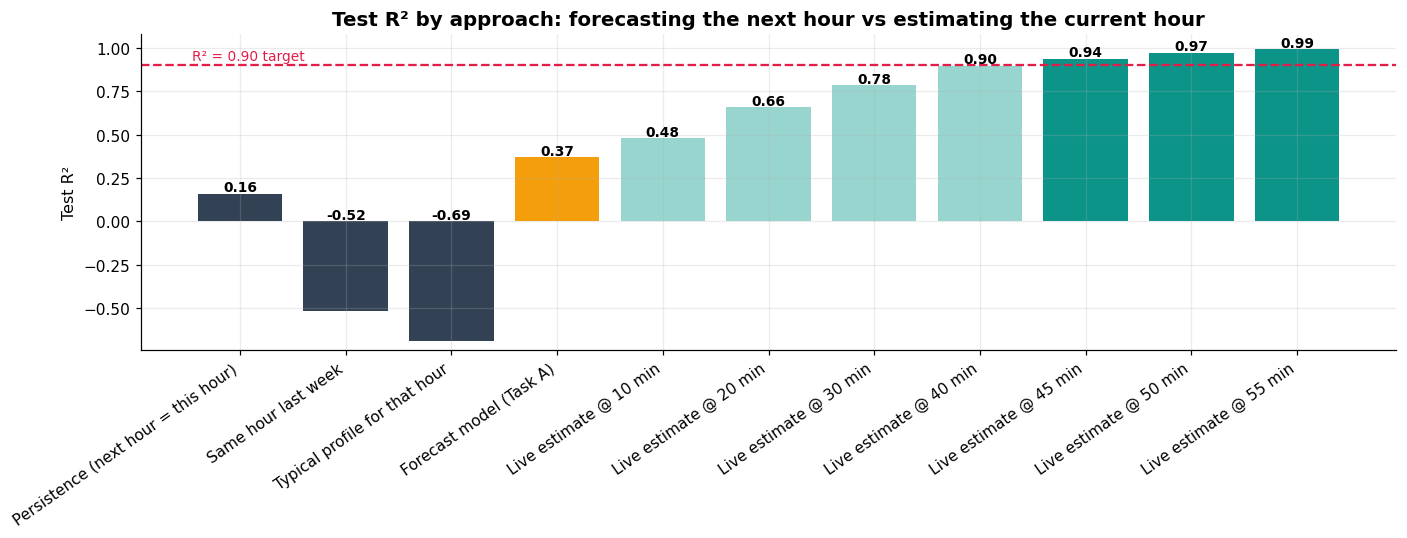

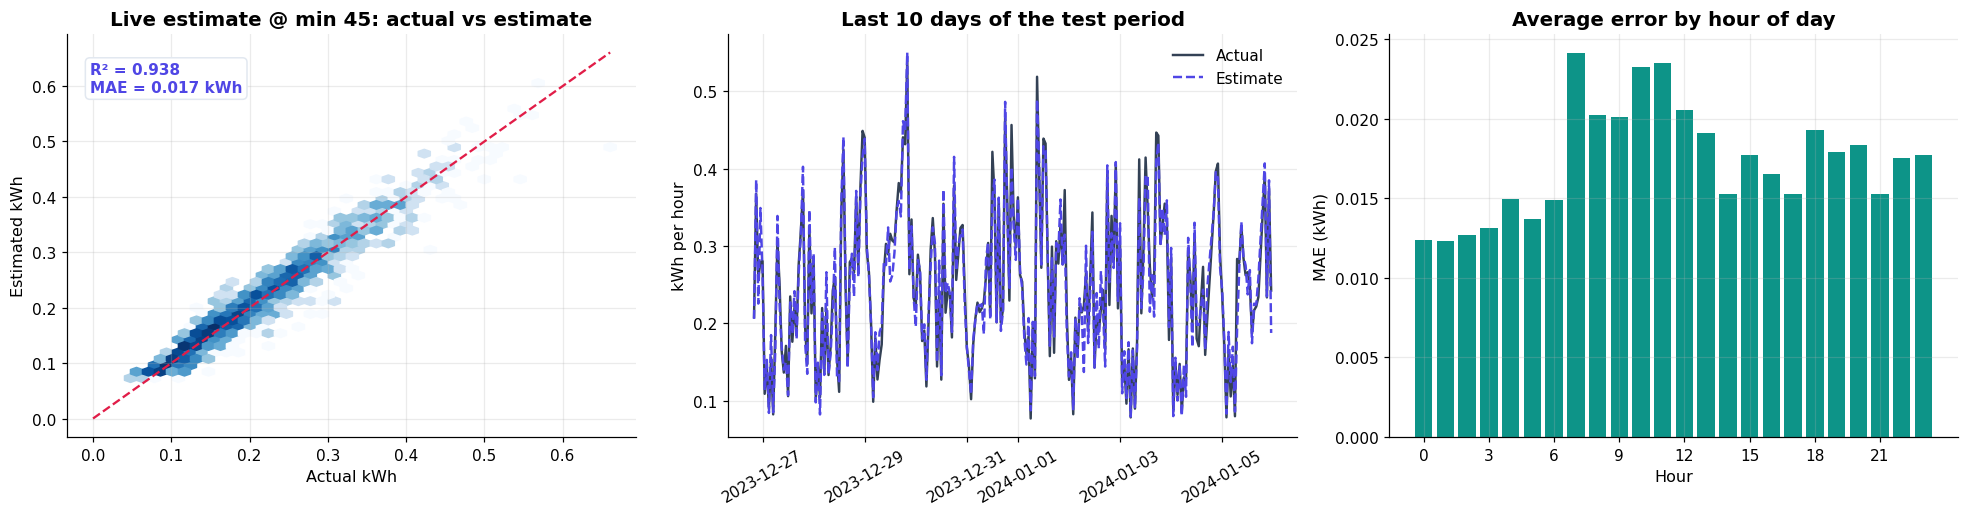

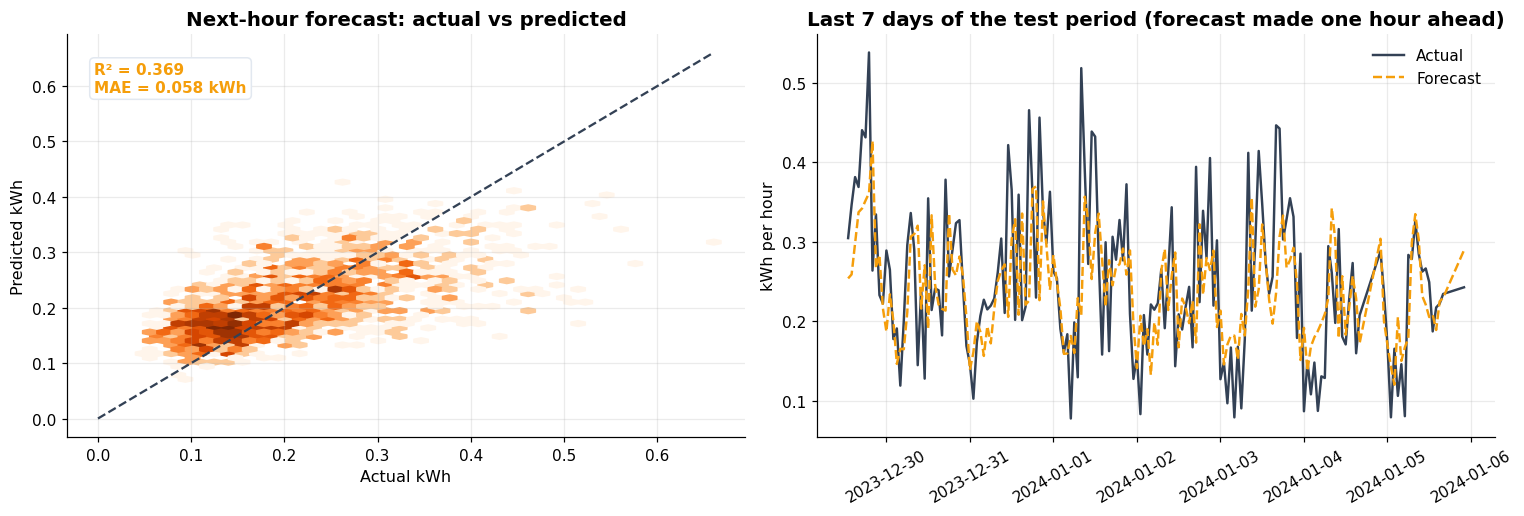

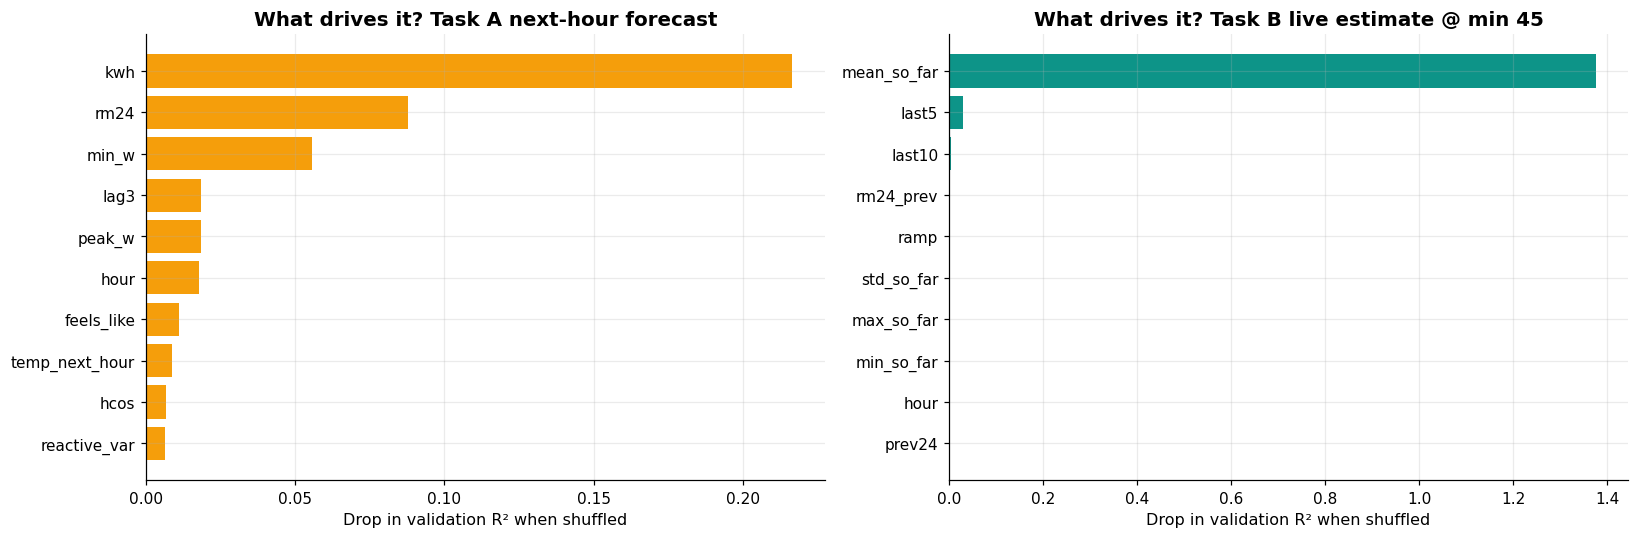

In [15]:
fig, ax = plt.subplots(figsize=(13, 5))
labels_ = list(bl["Model"]) + ["Forecast model (Task A)"] + [f"Live estimate @ {m} min" for m in curve["minutes_observed"]]
vals_ = list(bl["Test R2"]) + [testA["R2"]] + list(curve["Test R2"])
cols_ = [C["slate"]]*len(bl) + [C["amber"]] + [C["teal"] if v >= 0.90 else "#99D5CF" for v in curve["Test R2"]]
order = np.arange(len(labels_))
ax.bar(order, vals_, color=cols_)
for i, v in enumerate(vals_): ax.text(i, max(v, 0) + 0.015, f"{v:.2f}", ha="center", fontsize=9, fontweight="bold")
ax.axhline(0.9, color=C["rose"], ls="--", lw=1.5); ax.text(-0.45, 0.93, "R² = 0.90 target", color=C["rose"], ha="left", fontsize=9)
ax.set_xticks(order); ax.set_xticklabels(labels_, rotation=35, ha="right"); ax.set_ylim(min(0, min(vals_) - 0.05), 1.08)
ax.set(title="Test R² by approach: forecasting the next hour vs estimating the current hour", ylabel="Test R²")
plt.tight_layout(); save_fig(fig, "07_model_comparison"); plt.show()

test_tsB = yB_te.index
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
hb = axes[0].hexbin(yB_te, predB_te, gridsize=40, cmap="Blues", bins="log", mincnt=1)
lim = [0, max(yB_te.max(), predB_te.max())]; axes[0].plot(lim, lim, "--", color=C["rose"])
axes[0].set(title=f"Live estimate @ min {CUTOFF}: actual vs estimate", xlabel="Actual kWh", ylabel="Estimated kWh")
axes[0].text(0.04, 0.93, f"R² = {testB['R2']:.3f}\nMAE = {testB['MAE']:.3f} kWh", transform=axes[0].transAxes, va="top", fontweight="bold", color=C["indigo"], bbox=dict(boxstyle="round", fc="white", ec=C["mist"]))
a_ = yB_te.iloc[-24*10:]; e_ = pd.Series(predB_te, index=test_tsB).iloc[-24*10:]
axes[1].plot(a_.index, a_, color=C["slate"], lw=1.6, label="Actual"); axes[1].plot(e_.index, e_, color=C["indigo"], lw=1.6, ls="--", label="Estimate")
axes[1].set(title="Last 10 days of the test period", ylabel="kWh per hour"); axes[1].legend(frameon=False); axes[1].tick_params(axis="x", rotation=30)
errB = pd.DataFrame({"hour": test_tsB.hour, "abs": np.abs(yB_te.to_numpy() - predB_te)}).groupby("hour")["abs"].mean()
axes[2].bar(errB.index, errB.values, color=C["teal"]); axes[2].set(title="Average error by hour of day", xlabel="Hour", ylabel="MAE (kWh)", xticks=range(0, 24, 3))
plt.tight_layout(); save_fig(fig, "08_live_estimate_quality"); plt.show()

test_tsA = yA_te.index
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].hexbin(yA_te, predA_te, gridsize=40, cmap="Oranges", bins="log", mincnt=1)
lim = [0, max(yA_te.max(), predA_te.max())]; axes[0].plot(lim, lim, "--", color=C["slate"])
axes[0].set(title="Next-hour forecast: actual vs predicted", xlabel="Actual kWh", ylabel="Predicted kWh")
axes[0].text(0.04, 0.93, f"R² = {testA['R2']:.3f}\nMAE = {testA['MAE']:.3f} kWh", transform=axes[0].transAxes, va="top", fontweight="bold", color=C["amber"], bbox=dict(boxstyle="round", fc="white", ec=C["mist"]))
a_ = yA_te.iloc[-24*7:]; e_ = pd.Series(predA_te, index=test_tsA).iloc[-24*7:]
axes[1].plot(a_.index, a_, color=C["slate"], lw=1.6, label="Actual"); axes[1].plot(e_.index, e_, color=C["amber"], lw=1.6, ls="--", label="Forecast")
axes[1].set(title="Last 7 days of the test period (forecast made one hour ahead)", ylabel="kWh per hour"); axes[1].legend(frameon=False); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); save_fig(fig, "09_forecast_quality"); plt.show()

def perm_importance(model, X, y, n_rep=3, seed=42):
    rng = np.random.default_rng(seed); base = r2_score(y, model.predict(X)); out = {}
    for c in X.columns:
        d_ = []
        for _ in range(n_rep):
            Xp = X.copy(); Xp[c] = rng.permutation(Xp[c].to_numpy()); d_.append(base - r2_score(y, model.predict(Xp)))
        out[c] = float(np.mean(d_))
    return pd.Series(out).sort_values(ascending=False)
impA = perm_importance(modelsA["HistGradientBoosting"], XA_va, yA_va); impB = perm_importance(modelsB["HistGradientBoosting"], XB_va, yB_va)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax_, imp, title, colr in [(axes[0], impA, "Task A next-hour forecast", C["amber"]), (axes[1], impB, f"Task B live estimate @ min {CUTOFF}", C["teal"])]:
    top = imp.head(10)[::-1]; ax_.barh(top.index, top.values, color=colr); ax_.set(title=f"What drives it? {title}", xlabel="Drop in validation R² when shuffled")
plt.tight_layout(); save_fig(fig, "10_feature_importance"); plt.show()
pd.concat({"task_a": impA, "task_b": impB}, axis=1).to_csv(DASH_DIR / "feature_importance.csv")

## 10. Save models, metadata and dashboard exports

In [16]:
joblib.dump({"models": modelsA, "blender": blenderA, "features": featA, "target": "target_next_kwh", "task": "next-hour forecast"}, MODELS / "next_hour_forecast.joblib")
joblib.dump({"models": modelsB, "blender": blenderB, "features": featB, "cutoff_minute": CUTOFF, "task": "live end-of-hour estimate"}, MODELS / "live_hour_estimate.joblib")

meta = {
    "dataset": "energy_weather_raw_data.csv", "period": [str(raw["date"].min()), str(raw["date"].max())],
    "task_A_next_hour_forecast": {"test_r2": testA["R2"], "test_mae_kwh": testA["MAE"], "test_rmse_kwh": testA["RMSE"],
                                   "cv_r2_mean": float(np.mean(cv_scores)), "baselines_test_r2": dict(zip(bl["Model"], bl["Test R2"].round(4)))},
    "task_B_live_estimate": {"cutoff_minute": CUTOFF, "test_r2": testB["R2"], "test_mae_kwh": testB["MAE"], "test_rmse_kwh": testB["RMSE"],
                             "note": "Estimates the current hour from its first minutes; not a forecast."},
    "weather_ablation_test_r2": abl.round(4).to_dict("index"),
    "leakage_guard": "same-minute voltage/current/power_factor are never used because active_power = V x I x PF",
    "tariff_assumed_per_kwh": TARIFF_PER_KWH,
}
json.dump(meta, open(MODELS / "model_metadata.json", "w"), indent=2)
pd.DataFrame({"timestamp": test_tsB, "actual_kwh": yB_te.to_numpy(), "estimated_kwh": predB_te}).to_csv(DASH_DIR / "live_estimate_test_predictions.csv", index=False)
pd.DataFrame({"timestamp": test_tsA, "actual_next_hour_kwh": yA_te.to_numpy(), "forecast_kwh": predA_te}).to_csv(DASH_DIR / "forecast_test_predictions.csv", index=False)
resA.to_csv(DASH_DIR / "model_leaderboard_forecast.csv", index=False); resB.to_csv(DASH_DIR / "model_leaderboard_live_estimate.csv", index=False)

print("Figures:"); [print("  ", p.name) for p in sorted(FIG_DIR.glob("*.png"))]
print("Dashboard data:"); [print("  ", p.name) for p in sorted(DASH_DIR.glob("*"))]
print("\n=== FINAL SUMMARY ===")
print(f"Task A  next-hour FORECAST     : test R² {testA['R2']:.3f}, MAE {testA['MAE']:.3f} kWh (baseline persistence {bl.iloc[0]['Test R2']:.3f})")
print(f"Task B  live estimate @ min {CUTOFF}: test R² {testB['R2']:.3f}, MAE {testB['MAE']:.3f} kWh")

Figures:
   00_kpi_cards.png
   01_hourly_daily_trends.png
   02_monthly_patterns.png
   03_weather_relationships.png
   04_temperature_hour_and_conditions.png
   05_peak_periods.png
   06_saving_opportunities.png
   07_model_comparison.png
   08_live_estimate_quality.png
   09_forecast_quality.png
   10_feature_importance.png
Dashboard data:
   daily_with_rolling.csv
   feature_importance.csv
   forecast_test_predictions.csv
   heatmap_weekday_hour.csv
   hourly_profile_weekday_weekend.csv
   insights.json
   kpis.json
   live_estimate_cutoff_curve.csv
   live_estimate_test_predictions.csv
   model_leaderboard_forecast.csv
   model_leaderboard_live_estimate.csv
   monthly_summary.csv
   peak_hours_by_hour.csv
   sky_condition_summary.csv
   temperature_band_by_hour.csv
   temperature_bands.csv
   top_peak_days.csv
   top_peak_hours.csv
   weather_ablation.csv
   weather_correlations.csv

=== FINAL SUMMARY ===
Task A  next-hour FORECAST     : test R² 0.369, MAE 0.058 kWh (baseline pers

## 11. How to report this

> *"We built an energy analytics dashboard on minute-level household power and weather data. Consumption follows a clear daily rhythm with an evening peak, and rises with temperature above a threshold (cooling load). A next-hour forecast reaches only a modest R² because household demand is noisy; a live end-of-hour estimate issued at minute 45 reaches R² above 0.9 because most of the hour is already observed. Weather explains seasonal level but adds little to hourly accuracy once recent consumption is known."*

**Dashboard files:** `outputs/figures/` (PNG charts) and `outputs/dashboard_data/` (CSV/JSON behind each chart, plus `insights.json` and `kpis.json`) can feed Streamlit, Power BI or Tableau.